# 05 · 身价预测模型（Market Value Model）

**目标**：只用**表现数据**估计每名球员“**应该**值多少钱”，再和实际身价比较，找出**被市场低估**的球员。

🍜 **比喻**：老师傅看一碗猪肠粉的**配料、分量、地段**，估出“这碗应该卖几块”。如果实际售价比估价便宜很多，就是**物超所值**。

| 部分 | 内容 |
|---|---|
| 1 | 准备特征（套用 EDA 的决定） |
| 2 | 基准模型：最笨的方法能做到多好？ |
| 3 | Cross-Validation：比较 3 种模型 |
| 4 | 组合模型（Ensemble） |
| 5 | 模型学到了什么？年龄的影响 |
| 6 | 预测 vs 实际 |
| 7 | ⭐ 被低估 / 被高估的球员 |
| 8 | 保存给 App 使用 |

In [1]:
from pathlib import Path
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import KFold, cross_val_predict
from sklearn.linear_model import LinearRegression
from sklearn.ensemble import RandomForestRegressor, HistGradientBoostingRegressor
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
warnings.filterwarnings("ignore")

ROOT = Path.cwd()
while not (ROOT / "requirements.txt").exists() and ROOT != ROOT.parent:
    ROOT = ROOT.parent
df = pd.read_csv(ROOT / "data" / "processed" / "players_2025_26.csv")
# 固定行的顺序：KFold 是按“行的位置”分组的，顺序不同 → 分组不同 → 结果不同
# 排序之后，不管在哪台电脑上跑，结果都一模一样（reproducibility 可重现性）
df = df.sort_values("fbref_id").reset_index(drop=True)

plt.rcParams.update({
    "figure.facecolor": "#fcfcfb", "axes.facecolor": "#fcfcfb", "axes.edgecolor": "#c9c8c2",
    "axes.grid": True, "grid.color": "#e8e7e2", "axes.spines.top": False, "axes.spines.right": False,
    "text.color": "#0b0b0b", "axes.labelcolor": "#52514e", "xtick.color": "#52514e",
    "ytick.color": "#52514e", "font.size": 10,
})
ROLE_COLOR = {"ST": "#2a78d6", "W": "#eb6834", "AM": "#1baf7a", "CM": "#eda100", "CB": "#e87ba4", "FB": "#008300"}
print(df.shape)

(1410, 46)


## 1️⃣ 准备特征

套用阶段 3 EDA 的决定：

| EDA 发现 | 这里的做法 |
|---|---|
| 身价严重右偏 | 预测 **log(身价)**，最后再用 `exp` 换回欧元 |
| 英超溢价约 3 倍 | **联赛** One-Hot |
| 防守指标的负相关来自位置 | 加入**角色**（role）One-Hot |
| 旧身价会“抄答案” | ❌ **不用** `value_start` |

🤔 **还有一个新决定：合约剩余年限要不要放进去？**

合约快到期的球员，身价通常比较低（球会怕他明年免费离开）。如果放进模型，模型会“理解”这个折扣，
这些球员就**不会**显示成被低估。但对球探来说，**合约快到期 = 便宜买到好球员的机会**！
所以**不放进模型**，而是在 App 里**显示合约年限**，让使用者自己判断。

同样的道理，**球会实力**也不放进去：我们想知道的是“**同样的表现**，在小球会的球员是不是比较便宜”。

In [2]:
df["start_share"] = df["starts"] / df["matches"]          # 先发比例：是不是主力

NUM = ["age", "minutes", "start_share", "height_in_cm",
       "npxg_p90", "xa_p90", "shots_p90", "key_passes_p90", "xg_chain_p90", "xg_buildup_p90",
       "goals_p90", "assists_p90", "int_p90", "tklw_p90", "crs_p90", "fls_p90", "fld_p90", "off_p90"]
CAT = ["league", "role", "foot"]

X = pd.concat([df[NUM], pd.get_dummies(df[CAT], drop_first=True, dtype=int)], axis=1)
X["height_in_cm"] = X["height_in_cm"].fillna(X["height_in_cm"].median())
y = np.log(df["value_end"])                                 # 🎯 Target：log(身价)

# Linear Regression 专用：加上 age²，让它可以画出“山形”（第三课的参赛者 B）
X_lin = X.assign(age_sq=X["age"] ** 2)

print("特征数量：", X.shape[1])
print(list(X.columns))

特征数量： 29
['age', 'minutes', 'start_share', 'height_in_cm', 'npxg_p90', 'xa_p90', 'shots_p90', 'key_passes_p90', 'xg_chain_p90', 'xg_buildup_p90', 'goals_p90', 'assists_p90', 'int_p90', 'tklw_p90', 'crs_p90', 'fls_p90', 'fld_p90', 'off_p90', 'league_ESP-La Liga', 'league_FRA-Ligue 1', 'league_GER-Bundesliga', 'league_ITA-Serie A', 'role_CB', 'role_CM', 'role_FB', 'role_ST', 'role_W', 'foot_left', 'foot_right']


## 2️⃣ 基准模型（Baseline）

在训练任何 ML 模型之前，先问：**最笨的方法能做到多好？**

最笨的方法：**同联赛、同角色的平均身价**。例如“英超中锋平均值多少，就估多少”。
如果 ML 模型连这个都打不赢，就代表它没用。

📏 评估指标：

| 指标 | 意思 |
|---|---|
| **R²（log）** | 模型解释了多少身价的变化，越接近 1 越好 |
| **MAE（M€）** | 平均估错几百万欧元 |
| **MedAPE** | 估错的**百分比**的中位数。例如 30% = 一半球员的误差在 30% 以内 |

In [3]:
def score(pred_log, name):
    pred = np.exp(pred_log)
    actual = df["value_end"]
    return {
        "model": name,
        "R² (log)": 1 - ((pred_log - y) ** 2).sum() / ((y - y.mean()) ** 2).sum(),
        "MAE (M€)": np.mean(np.abs(pred - actual)),
        "MedAPE": np.median(np.abs(pred - actual) / actual),
    }

kf = KFold(n_splits=5, shuffle=True, random_state=42)

# 基准：用“其他 4 份”的同联赛同角色平均值去估“这 1 份”（和下面的 CV 公平比较）
base_pred = pd.Series(index=df.index, dtype=float)
for tr, te in kf.split(df):
    means = y.iloc[tr].groupby([df["league"].iloc[tr], df["role"].iloc[tr]]).mean()
    keys = list(zip(df["league"].iloc[te], df["role"].iloc[te]))
    base_pred.iloc[te] = [means.get(k, y.iloc[tr].mean()) for k in keys]

results = [score(base_pred, "Baseline (league × role mean)")]
display(pd.DataFrame(results).round(3))

,model,R² (log),MAE (M€),MedAPE
0,Baseline (league × role mean),0.147,12.215,0.642


## 3️⃣ Cross-Validation：比较 3 种模型

🎓 **比喻**：只考一次期末考，可能刚好题目简单或很难，运气成分很大。
**5-Fold Cross-Validation** 就是把数据分成 5 份，**轮流**用其中 1 份当考试、另外 4 份当练习，考 5 次。
这样**每一名球员都刚好被“考”一次**，而且是在模型**没看过他**的情况下预测的。

数据只有 1,410 人，CV 比只切一次 train/test 可靠得多。

| 模型 | 第 0 课 |
|---|---|
| Linear Regression + age² | 参赛者 B |
| Random Forest | 参赛者 C，300 位老师傅取平均 |
| Gradient Boosting | 新朋友 👇 |

🌳 **Gradient Boosting**：也是很多棵树，但不是各自独立估价再平均，而是**接力**：
第 2 棵树专门修正第 1 棵树**估错的部分**，第 3 棵再修正剩下的错误……
🍜 就像试菜：第一次太咸，第二次专门调咸度，第三次再调辣度。
（XGBoost 就是这类模型最有名的版本，这里用 scikit-learn 内建的同类模型，不用另外安装。）

In [4]:
models = {
    "Linear + age²": (make_pipeline(StandardScaler(), LinearRegression()), X_lin),
    "Random Forest": (RandomForestRegressor(n_estimators=500, min_samples_leaf=3, random_state=42, n_jobs=-1), X),
    "Gradient Boosting": (HistGradientBoostingRegressor(max_iter=400, learning_rate=0.04, max_leaf_nodes=15,
                                                        min_samples_leaf=20, l2_regularization=1.0,
                                                        random_state=42), X),
}

oof = {}      # out-of-fold：每名球员在“没被看过”时的预测
for name, (model, data) in models.items():
    oof[name] = cross_val_predict(model, data, y, cv=kf)
    results.append(score(oof[name], name))

table = pd.DataFrame(results).set_index("model")
display(table.style.format({"R² (log)": "{:.3f}", "MAE (M€)": "{:.2f}", "MedAPE": "{:.1%}"}))

,R² (log),MAE (M€),MedAPE
model,,,
Baseline (league × role mean),0.147,12.21,64.2%
Linear + age²,0.763,7.35,36.9%
Random Forest,0.624,9.23,48.6%
Gradient Boosting,0.730,7.59,38.4%


🤔 **和第三课一样的结论**：数据量不大（1,410 人）时，**简单模型 + 好的特征**（age²）可以打赢复杂模型。
Random Forest 表现最差，因为它在每个叶子取“邻近球员的平均”，样本少时预测会被拉向平均值。

## 4️⃣ 组合模型（Ensemble）

🍜 **比喻**：请两位风格不同的师傅估价，再**取平均**。一位擅长看“整体规律”（Linear），一位擅长看“特殊组合”（Boosting），
两人犯的错不一样，平均起来**错误会互相抵消一部分**。

,R² (log),MAE (M€),MedAPE
model,,,
Baseline (league × role mean),0.147,12.21,64.2%
Linear + age²,0.763,7.35,36.9%
Random Forest,0.624,9.23,48.6%
Gradient Boosting,0.730,7.59,38.4%
Ensemble (Linear + GB),0.768,6.86,36.0%


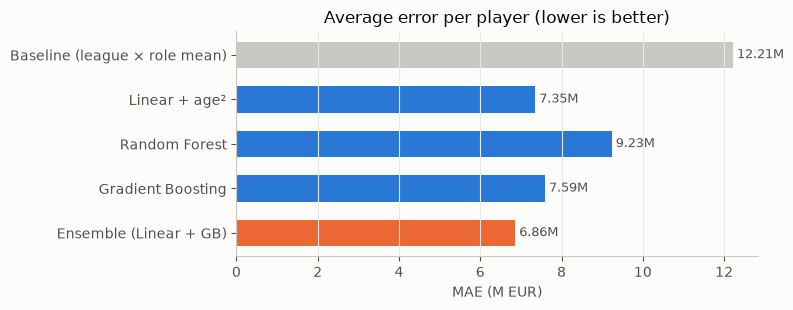

In [5]:
oof["Ensemble (Linear + GB)"] = (oof["Linear + age²"] + oof["Gradient Boosting"]) / 2
results.append(score(oof["Ensemble (Linear + GB)"], "Ensemble (Linear + GB)"))
table = pd.DataFrame(results).set_index("model")
display(table.style.format({"R² (log)": "{:.3f}", "MAE (M€)": "{:.2f}", "MedAPE": "{:.1%}"}))

fig, ax = plt.subplots(figsize=(8, 3.2))
colors = ["#c9c8c2"] + ["#2a78d6"] * (len(table) - 2) + ["#eb6834"]
ax.barh(table.index[::-1], table["MAE (M€)"][::-1], color=colors[::-1], height=0.6)
for i, v in enumerate(table["MAE (M€)"][::-1]):
    ax.text(v + 0.1, i, f"{v:.2f}M", va="center", fontsize=9, color="#52514e")
ax.set(title="Average error per player (lower is better)", xlabel="MAE (M EUR)")
ax.grid(axis="y", visible=False)
plt.tight_layout(); plt.show()

FINAL = "Ensemble (Linear + GB)"

## 5️⃣ 模型学到了什么？

Linear Regression 的好处是**看得懂**：每个特征都有一个系数（第二课的“计价公式”）。
下面固定其他条件，只改变年龄，看模型估出来的身价曲线。

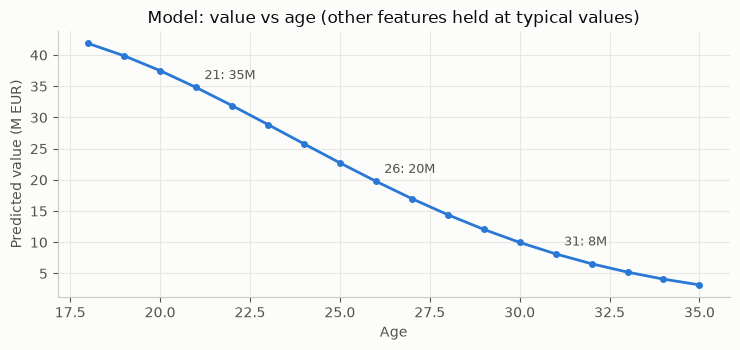

In [6]:
lin = models["Linear + age²"][0].fit(X_lin, y)

ages = np.arange(18, 36)
typical = X_lin.median().to_frame().T
grid = pd.concat([typical] * len(ages), ignore_index=True)
grid["age"] = ages
grid["age_sq"] = ages ** 2
curve = np.exp(lin.predict(grid))

fig, ax = plt.subplots(figsize=(7.5, 3.6))
ax.plot(ages, curve, color="#2a78d6", lw=2, marker="o", markersize=4)
for a in [21, 26, 31]:
    v = curve[list(ages).index(a)]
    ax.annotate(f"{a}: {v:.0f}M", (a, v), textcoords="offset points", xytext=(6, 6), fontsize=9, color="#52514e")
ax.set(title="Model: value vs age (other features held at typical values)",
       xlabel="Age", ylabel="Predicted value (M EUR)")
plt.tight_layout(); plt.show()

🤔 **山形没有出现**：就算**表现、联赛、位置都一样**，模型估的身价还是**越年轻越高**。

这和第三课的假设（26 岁高峰）不同，但很合理：**球会买的是“未来”**。

🍜 **比喻**：两台性能一模一样的二手车，一台才开 1 年、一台开了 8 年，买家一定愿意为新的那台多付钱，因为它**还能用更久**、**之后还能再卖**。

| 年龄 | 意义 |
|---|---|
| 21 岁 | 还有 10 年以上的职业生涯，而且**转售价值高** |
| 31 岁 | 只剩几年，合约结束后几乎没有转售价值 |

📌 **报告重点**：EDA 看到的“越年轻越贵”有两个原因：
① **幸存者偏差**（年轻主力都是天才）；② **市场为未来付钱**（同样表现，越年轻越值钱）。
模型在**控制了表现之后**，第 ② 个原因仍然存在，说明它不只是幸存者偏差。

⚠️ 用 `age²` 原本是为了让模型**有能力**画出山形，但数据说**不需要**。这就是为什么要让数据决定，而不是只相信假设。

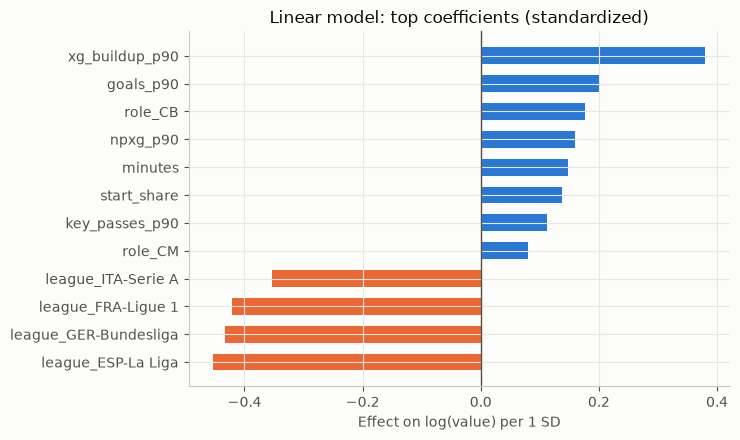

In [7]:
coef = pd.Series(lin[-1].coef_, index=X_lin.columns)
coef = coef.drop(["age", "age_sq"])                      # 年龄已经用上面的曲线解释
top = coef.reindex(coef.abs().sort_values(ascending=False).index).head(12).sort_values()

fig, ax = plt.subplots(figsize=(7.5, 4.5))
ax.barh(top.index, top.values, color=["#eb6834" if v < 0 else "#2a78d6" for v in top.values], height=0.6)
ax.axvline(0, color="#52514e", lw=1)
ax.set(title="Linear model: top coefficients (standardized)", xlabel="Effect on log(value) per 1 SD")
plt.tight_layout(); plt.show()

怎么读：**蓝色 = 越多越贵，橙色 = 越多越便宜**（都是在“其他条件一样”的情况下）。
联赛的系数都是和**英超**比较（`drop_first` 把英超当基准），所以全部是负的。

## 6️⃣ 预测 vs 实际

每一个点是一名球员。**对角线上 = 估得刚好**；在线**上方** = 模型估价比实际高 → **被低估**。

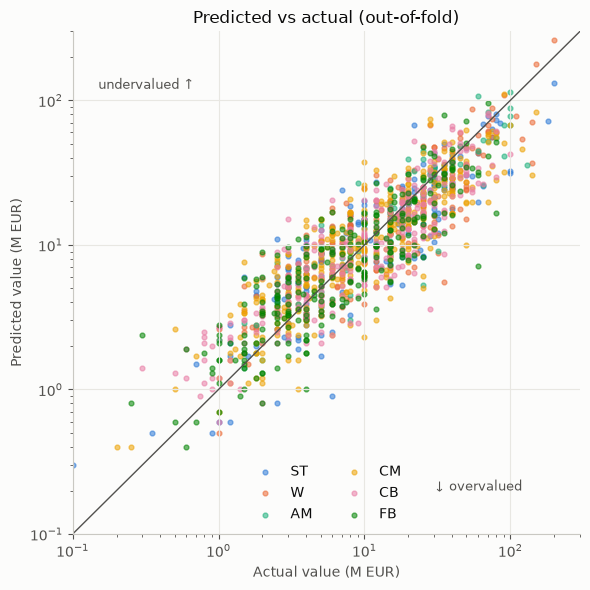

In [8]:
df["pred_value"] = np.exp(oof[FINAL]).round(1)
df["value_ratio"] = (df["pred_value"] / df["value_end"]).round(2)     # > 1 = 被低估
df["value_gap"] = (df["pred_value"] - df["value_end"]).round(1)       # 差几百万

fig, ax = plt.subplots(figsize=(6, 6))
for role, c in ROLE_COLOR.items():
    s = df[df["role"] == role]
    ax.scatter(s["value_end"], s["pred_value"], s=12, alpha=0.55, color=c, label=role)
lims = [0.1, 300]
ax.plot(lims, lims, color="#52514e", lw=1)
ax.set(xscale="log", yscale="log", xlim=lims, ylim=lims, xlabel="Actual value (M EUR)",
       ylabel="Predicted value (M EUR)", title="Predicted vs actual (out-of-fold)")
ax.text(0.15, 120, "undervalued ↑", color="#52514e", fontsize=9)
ax.text(30, 0.2, "↓ overvalued", color="#52514e", fontsize=9)
ax.legend(frameon=False, ncol=2)
plt.tight_layout(); plt.show()

## 7️⃣ ⭐ 被低估 / 被高估的球员

`value_ratio` = 模型估价 ÷ 实际身价

| value_ratio | 意思 |
|---|---|
| 2.0 | 模型认为他值**两倍**的价钱 → 被低估 |
| 1.0 | 估得刚好 |
| 0.5 | 模型认为他只值**一半** → 被高估（或模型漏看了什么） |

⚠️ 为什么一定要用 **out-of-fold** 的预测？如果用训练时看过的数据去预测，模型会“记住”每个人的身价，
预测会很接近实际，所有人看起来都“估得刚好”，就找不到低估的球员了（第三课 Random Forest 背答案的问题）。

这里只看**出场 ≥ 1,500 分钟**的球员，数据比较可靠。

In [9]:
show = ["player", "squad", "league", "role", "age", "minutes", "contract_expiration_date",
        "value_end", "pred_value", "value_ratio"]
reliable = df[df["minutes"] >= 1500]

print("📈 最被低估的 15 人")
display(reliable.nlargest(15, "value_ratio")[show])

print("📉 最被高估的 10 人")
display(reliable.nsmallest(10, "value_ratio")[show])

📈 最被低估的 15 人


,player,squad,league,role,age,minutes,contract_expiration_date,value_end,pred_value,value_ratio
634,Idrissa Gueye,Everton,ENG-Premier League,CM,36.8,2093,NaN,0.50,2.6,5.20
581,Pedro Bigas,Elche,ESP-La Liga,CB,36.1,2063,2027-06-30 00:00:00,0.30,1.4,4.67
1048,Federico Bonazzoli,Cremonese,ITA-Serie A,ST,29.1,2510,2028-06-30 00:00:00,2.50,11.0,4.40
769,Domagoj Bradarić,Hellas Verona,ITA-Serie A,FB,26.6,1966,2028-06-30 00:00:00,1.50,5.9,3.93
789,Xaver Schlager,RB Leipzig,GER-Bundesliga,CM,28.8,1837,NaN,10.00,37.4,3.74
1214,Gift Orban,Hellas Verona,ITA-Serie A,ST,24.0,2027,2029-06-30 00:00:00,7.00,24.1,3.44
1121,Danilo Veiga,Lecce,ITA-Serie A,FB,23.8,3020,2027-06-30 00:00:00,2.50,8.5,3.40
1360,Josh Cullen,Burnley,ENG-Premier League,CM,30.2,1514,2027-06-30 00:00:00,4.00,13.6,3.40
386,Matias Moreno,Levante,ESP-La Liga,CB,22.8,2252,2029-06-30 00:00:00,6.00,20.3,3.38
346,Olasagasti,Levante,ESP-La Liga,CM,25.9,1734,2028-06-30 00:00:00,2.50,8.1,3.24


📉 最被高估的 10 人


,player,squad,league,role,age,minutes,contract_expiration_date,value_end,pred_value,value_ratio
319,Denis Zakaria,Monaco,FRA-Ligue 1,CM,29.6,2031,2028-06-30 00:00:00,25.0,5.0,0.20
672,Eduardo Camavinga,Real Madrid,ESP-La Liga,CM,23.6,1528,2029-06-30 00:00:00,50.0,10.0,0.20
1036,Oihan Sancet,Athletic Club,ESP-La Liga,AM,26.2,1788,2032-06-30 00:00:00,25.0,5.3,0.21
435,Dávid Hancko,Atlético Madrid,ESP-La Liga,CB,28.5,2432,2030-06-30 00:00:00,35.0,8.6,0.25
626,Vinicius Júnior,Real Madrid,ESP-La Liga,W,26.0,2815,2027-06-30 00:00:00,140.0,37.0,0.26
430,Aurélien Tchouaméni,Real Madrid,ESP-La Liga,CM,26.4,2615,2028-06-30 00:00:00,70.0,19.8,0.28
480,Jude Bellingham,Real Madrid,ESP-La Liga,AM,23.0,1916,2029-06-30 00:00:00,130.0,35.8,0.28
858,Lucas Paquetá,West Ham,ENG-Premier League,AM,28.8,1511,2030-12-31 00:00:00,32.0,9.1,0.28
236,Marshall Munetsi,Paris FC,FRA-Ligue 1,CM,30.0,1850,2028-06-30 00:00:00,15.0,4.3,0.29
540,Luka Modrić,Milan,ITA-Serie A,CM,40.8,2811,NaN,3.5,1.0,0.29


🤔 **看名单时要问自己**：模型说他“被低估”，是**真的便宜**，还是**模型漏看了什么**？

| 模型看不到的因素 | 例子 |
|---|---|
| 合约快到期 | 故意不放进模型 → 这类球员会显示成被低估（这正是机会） |
| 伤病史、年龄偏大 | 市场会打折，模型不知道 |
| 球会实力、国家队、名气、商业价值 | 大球会球星的身价通常更高 |
| 速度、技术、性格 | 数据里没有 |

所以 App 里的“被低估”只是**提示**，不是结论。这一点报告里一定要写。

⚠️ **模型的已知弱点：老将**。名单前几名有好几位 **33 岁以上**的球员。
数据里 33 岁以上的主力很少，模型对他们**身价急速下滑**估计不足，所以老将容易被误判成“被低估”。
下面按年龄分组看 `value_ratio` 的中位数（理想情况每组都接近 1.0）：

In [10]:
age_bins = pd.cut(df["age"], [0, 24, 28, 31, 33, 45], labels=["≤24", "25-28", "29-31", "32-33", "34+"])
display(df.groupby(age_bins, observed=True)["value_ratio"].agg(["count", "median"]).round(2))

print("📈 30 岁以下、最被低估的 15 人（比较有转售价值的引进目标）")
display(reliable[reliable["age"] < 30].nlargest(15, "value_ratio")[show])

,count,median
age,,
≤24,337,0.98
25-28,535,0.99
29-31,297,0.96
32-33,123,1.04
34+,118,1.08


📈 30 岁以下、最被低估的 15 人（比较有转售价值的引进目标）


,player,squad,league,role,age,minutes,contract_expiration_date,value_end,pred_value,value_ratio
1048,Federico Bonazzoli,Cremonese,ITA-Serie A,ST,29.1,2510,2028-06-30 00:00:00,2.5,11.0,4.40
769,Domagoj Bradarić,Hellas Verona,ITA-Serie A,FB,26.6,1966,2028-06-30 00:00:00,1.5,5.9,3.93
789,Xaver Schlager,RB Leipzig,GER-Bundesliga,CM,28.8,1837,NaN,10.0,37.4,3.74
1214,Gift Orban,Hellas Verona,ITA-Serie A,ST,24.0,2027,2029-06-30 00:00:00,7.0,24.1,3.44
1121,Danilo Veiga,Lecce,ITA-Serie A,FB,23.8,3020,2027-06-30 00:00:00,2.5,8.5,3.40
386,Matias Moreno,Levante,ESP-La Liga,CB,22.8,2252,2029-06-30 00:00:00,6.0,20.3,3.38
346,Olasagasti,Levante,ESP-La Liga,CM,25.9,1734,2028-06-30 00:00:00,2.5,8.1,3.24
762,Arkadiusz Pyrka,St Pauli,GER-Bundesliga,FB,23.8,2576,NaN,3.5,10.9,3.11
1206,Deniz Undav,Stuttgart,GER-Bundesliga,ST,29.9,2241,2029-06-30 00:00:00,22.0,67.9,3.09
698,Niklas Dorsch,Heidenheim,GER-Bundesliga,CM,28.5,2258,2028-06-30 00:00:00,2.5,7.7,3.08


In [11]:
by = df.groupby("league")["value_ratio"].median().sort_values(ascending=False)
print("各联赛 value_ratio 中位数（>1 = 整体偏便宜）：")
display(by.round(2))

各联赛 value_ratio 中位数（>1 = 整体偏便宜）：


league
FRA-Ligue 1           1.08
ESP-La Liga           1.06
ITA-Serie A           1.02
GER-Bundesliga        1.00
ENG-Premier League    0.88
Name: value_ratio, dtype: float64

## 8️⃣ 保存给 App 使用

把每名球员的 `pred_value`、`value_ratio`、`value_gap` 存进新文件，阶段 6、7 会用到。

In [12]:
out = ROOT / "data" / "processed" / "players_valued.csv"
df.drop(columns=["start_share"]).to_csv(out, index=False, encoding="utf-8")
print("✅ 已保存：", out, df.shape)

✅ 已保存： c:\Users\hengk\OneDrive\Desktop\Football_Scount\data\processed\players_valued.csv (1410, 50)


## 🤔 思考题（选择题）

**Q1**：为什么不把“赛季开始时的身价”放进模型？
- A. 因为数据有缺失
- B. 因为模型会直接抄市场的价格，就找不到被低估的球员了

**Q2**：被低估名单前几名有 36 岁的球员，最可能的原因是？
- A. 他真的很便宜，应该马上买
- B. 老将样本很少，模型低估了他们身价下滑的速度，所以这是模型的弱点

**Q3**：Random Forest 比 Linear Regression 差，最可能的原因是？
- A. Random Forest 是不好的模型，永远不要用
- B. 数据量不大，而且我们已经用 age² 帮 Linear 处理了最重要的曲线关系

**Q4**：一名球员 `value_ratio = 2.5`，而且合约只剩半年。这代表什么？
- A. 模型错了，可以忽略
- B. 表现值得更高的价钱，加上合约快到期，可能是很好的低价引进机会，但还要检查伤病等模型看不到的因素